# Grammar Scoring Engine — Audio-Based English Grammar Assessment

**SHL Hiring Assessment 2026 | Model evaluation and ensemble inference**

This notebook presents the final inference pipeline in a reproducible, review-friendly format. It covers data exploration, the saved model outputs, evaluation, ensemble construction, error analysis, and submission generation.

> **Execution note:** Expensive feature extraction and neural-model fine-tuning are intentionally not rerun. The notebook loads the saved out-of-fold (OOF) predictions and embeddings produced by the earlier experiments. It fits only the lightweight final regression components needed for evaluation and test-set inference.

**Previous submitted score:** 0.3412 on the competition public leaderboard. This is an external benchmark result, not a metric computed by this notebook.

## 1. Problem statement

The task is to predict a numerical grammar score from a spoken-English audio recording. The provided training data contains a filename and a target label; the test data contains filenames without labels.

The solution combines complementary representations of speech:

- **Canonical Whisper transcript → DeBERTa regressor:** captures grammar and meaning from a normalized transcript.
- **Verbatim Whisper transcript → DeBERTa regressor:** retains more spoken-language disfluencies and alternative wording.
- **Wav2Vec2 CTC transcript → DeBERTa regressor:** provides a distinct transcription view, which can contribute complementary errors.
- **WavLM audio representation → SVR:** uses acoustic information directly, without requiring a transcript.
- **Whisper encoder representation → RBF-SVR:** uses a high-dimensional audio representation with a nonlinear regression head.

The final stage combines their predictions using a non-negative linear regressor. The notebook evaluates the saved OOF predictions before fitting this final stack on all eligible OOF rows.

## 2. Pipeline architecture

The diagram below summarizes the artifacts used here. The feature extractors and neural regressors have already been run in the previous experiment; this notebook reuses their saved predictions rather than retraining them.

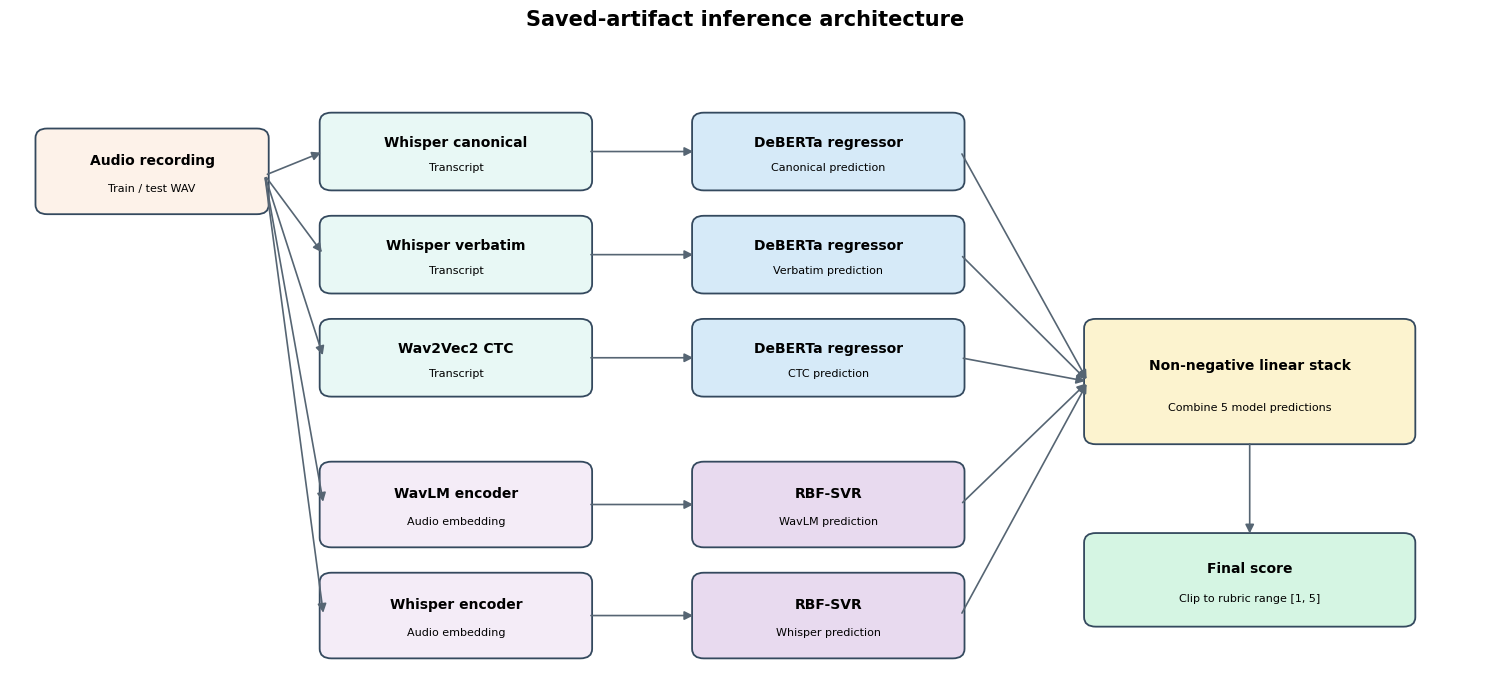

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlim(0, 15)
ax.set_ylim(0, 8)
ax.axis("off")

def box(x, y, w, h, title, subtitle="", color="#EAF2F8"):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.3, edgecolor="#34495E", facecolor=color
    )
    ax.add_patch(patch)
    ax.text(x+w/2, y+h*0.64, title, ha="center", va="center",
            fontsize=10, fontweight="bold", wrap=True)
    if subtitle:
        ax.text(x+w/2, y+h*0.29, subtitle, ha="center", va="center",
                fontsize=8, wrap=True)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>",
        mutation_scale=13, linewidth=1.2, color="#566573"
    ))

box(0.3, 5.9, 2.3, 1.0, "Audio recording", "Train / test WAV", "#FDF2E9")
box(3.2, 6.2, 2.7, 0.9, "Whisper canonical", "Transcript", "#E8F8F5")
box(3.2, 4.9, 2.7, 0.9, "Whisper verbatim", "Transcript", "#E8F8F5")
box(3.2, 3.6, 2.7, 0.9, "Wav2Vec2 CTC", "Transcript", "#E8F8F5")
box(3.2, 1.7, 2.7, 1.0, "WavLM encoder", "Audio embedding", "#F4ECF7")
box(3.2, 0.3, 2.7, 1.0, "Whisper encoder", "Audio embedding", "#F4ECF7")

box(7.0, 6.2, 2.7, 0.9, "DeBERTa regressor", "Canonical prediction", "#D6EAF8")
box(7.0, 4.9, 2.7, 0.9, "DeBERTa regressor", "Verbatim prediction", "#D6EAF8")
box(7.0, 3.6, 2.7, 0.9, "DeBERTa regressor", "CTC prediction", "#D6EAF8")
box(7.0, 1.7, 2.7, 1.0, "RBF-SVR", "WavLM prediction", "#E8DAEF")
box(7.0, 0.3, 2.7, 1.0, "RBF-SVR", "Whisper prediction", "#E8DAEF")

box(11.0, 3.0, 3.3, 1.5, "Non-negative linear stack", "Combine 5 model predictions", "#FCF3CF")
box(11.0, 0.7, 3.3, 1.1, "Final score", "Clip to rubric range [1, 5]", "#D5F5E3")

for yy in [6.65, 5.35, 4.05, 2.2, 0.8]:
    arrow(2.6, 6.35, 3.2, yy)
for y1, y2 in [(6.65,6.65),(5.35,5.35),(4.05,4.05),(2.2,2.2),(0.8,0.8)]:
    arrow(5.9, y1, 7.0, y2)
for yy in [6.65, 5.35, 4.05, 2.2, 0.8]:
    arrow(9.7, yy, 11.0, 3.75)
arrow(12.65, 3.0, 12.65, 1.8)

ax.set_title("Saved-artifact inference architecture", fontsize=15, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

## 3. Why these components were used

| Component | Reason for use | Limitation addressed |
|---|---|---|
| Canonical transcript | Normalized, readable text is useful for grammar patterns and sentence structure. | Reduces transcription noise. |
| Verbatim transcript | Preserves more spoken wording and disfluencies. | Avoids relying on a single transcript style. |
| CTC transcript | A different ASR method can make different recognition errors. | Adds diversity to the text branch. |
| DeBERTa regressors | Contextual language representations are suitable for predicting a continuous score. | Models word context rather than using only handcrafted counts. |
| WavLM + SVR | Uses speech acoustics directly and can capture information absent from text. | Adds an independent audio-only signal. |
| Whisper embeddings + SVR | Uses a second learned audio representation and nonlinear regression. | Adds representation diversity. |
| Non-negative linear stack | Learns how to combine model predictions while preventing negative weights. | Can exploit complementary predictions and keep combination interpretable. |

The final score is clipped to the valid non-zero rubric range \([1,5]\). Rows with a target label of zero are inspected in EDA but excluded from the main regression evaluation, consistent with the saved audio/Whisper artifacts and the earlier experiment.

## 4. Imports and reproducibility

In [2]:
import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.1.3
Pandas: 2.3.3


## 5. Locate data and saved artifacts

The paths below cover the standard Kaggle competition input and the previous notebook output. The helper checks known locations first, then searches those roots for a matching saved artifact. No neural model is loaded or retrained.

In [3]:
DATA_DIR = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")
TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"

if not TRAIN_CSV.exists() or not TEST_CSV.exists():
    raise FileNotFoundError(
        "Competition CSVs were not found. Attach the SHL Hiring Assessment 2026 "
        "competition dataset as a notebook input."
    )

SEARCH_ROOTS = [
    Path("/kaggle/working/shl_grammar_v2"),
    Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2"),
    Path("/kaggle/input"),
]

def find_artifact(filename, preferred=()):
    for path in preferred:
        path = Path(path)
        if path.is_file():
            return path
    for root in SEARCH_ROOTS:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                # Prefer the expected shl_grammar_v2 artifact tree.
                matches.sort(key=lambda p: ( "shl_grammar_v2" not in str(p), len(str(p)) ))
                return matches[0]
    raise FileNotFoundError(
        f"Could not find {filename}. Attach the previous notebook output "
        "containing the saved OOF predictions and embeddings."
    )

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))
print("Training columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
display(train_df.head())
display(test_df.head())

Training rows: 769
Test rows: 216
Training columns: ['filename', 'label']
Test columns: ['filename', 'label']


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


## 6. Data quality checks and target exploration

The target distribution is inspected before modelling. Zero-label rows are reported explicitly so that the evaluation population is transparent.

Total training rows: 769
Zero-label rows: 37
Eligible rows (label > 0): 732
Test rows: 216

Target summary (all training rows):


,label
count,769.000000
mean,3.313394
std,1.239000
min,0.000000
25%,2.500000
50%,3.000000
75%,4.000000
max,5.000000



Target counts:


,count
label,
0.0,37
1.0,1
1.5,3
2.0,102
2.5,79
3.0,174
3.5,64
4.0,124
4.5,52


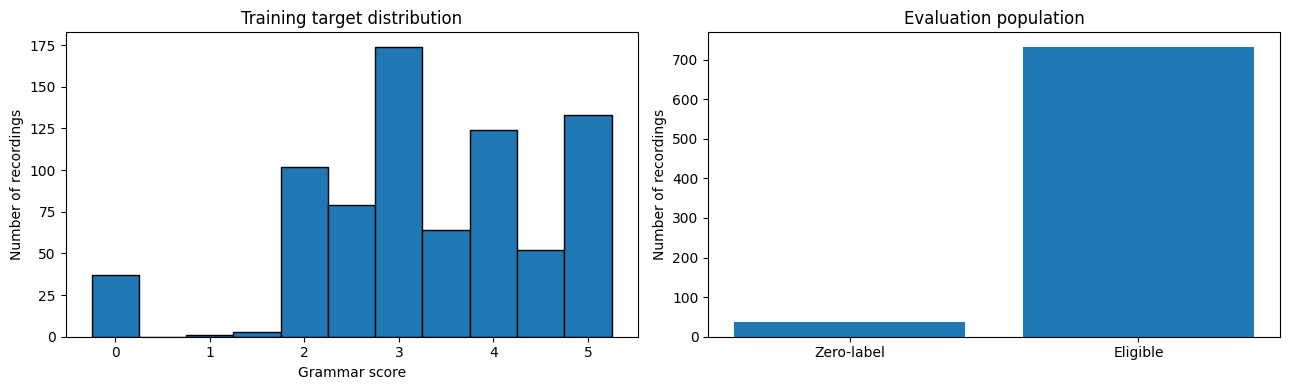

In [4]:
assert {"filename", "label"}.issubset(train_df.columns)
assert "filename" in test_df.columns
assert train_df["filename"].is_unique
assert test_df["filename"].is_unique
assert train_df["label"].notna().all()

zero_mask = train_df["label"].eq(0)
eligible_mask = train_df["label"].gt(0)
eligible_df = train_df.loc[eligible_mask].reset_index(drop=True)
y = eligible_df["label"].to_numpy(dtype=np.float64)

print(f"Total training rows: {len(train_df)}")
print(f"Zero-label rows: {int(zero_mask.sum())}")
print(f"Eligible rows (label > 0): {len(eligible_df)}")
print(f"Test rows: {len(test_df)}")
print("\nTarget summary (all training rows):")
display(train_df["label"].describe().to_frame("label"))
print("\nTarget counts:")
display(train_df["label"].value_counts().sort_index().rename_axis("label").to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train_df["label"], bins=np.arange(-0.25, 5.51, 0.5), edgecolor="black")
axes[0].set_title("Training target distribution")
axes[0].set_xlabel("Grammar score")
axes[0].set_ylabel("Number of recordings")
axes[1].bar(
    ["Zero-label", "Eligible"],
    [int(zero_mask.sum()), int(eligible_mask.sum())]
)
axes[1].set_title("Evaluation population")
axes[1].set_ylabel("Number of recordings")
plt.tight_layout()
plt.show()

## 7. Saved prediction artifacts

Each model's OOF predictions are used for training-set evaluation. OOF means each training prediction was intended to be generated without fitting that model on the corresponding validation example. The three transcript-model arrays include all 769 original training rows, so they are filtered using the exact target mask. The WavLM and Whisper OOF arrays are already stored for the 732 eligible rows.

**Alignment assumption:** these arrays were produced in the earlier notebook in the original CSV row order. Shape and filename checks are performed where metadata is available; the notebook cannot independently prove the training procedure used to create every saved array.

In [7]:
ROOT_WORK = Path("/kaggle/working/shl_grammar_v2")
PREV_OOF = Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof")
PREV_WHISPER = Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/whisper")

artifact_specs = {
    "CTC": {
        "oof": ("large_ctc_oof.npy", [
            ROOT_WORK / "oof/large_ctc_oof.npy",
            PREV_OOF / "large_ctc_oof.npy",
        ]),
        "test": ("large_ctc_test.npy", [
            ROOT_WORK / "oof/large_ctc_test.npy",
            PREV_OOF / "large_ctc_test.npy",
        ]),
        "full_train": True,
    },
    "Canonical": {
        "oof": ("large_canonical_oof.npy", [
            PREV_OOF / "large_canonical_oof.npy",
            ROOT_WORK / "oof/large_canonical_oof.npy",
        ]),
        "test": ("large_canonical_test.npy", [
            PREV_OOF / "large_canonical_test.npy",
            ROOT_WORK / "oof/large_canonical_test.npy",
        ]),
        "full_train": True,
    },
    "Verbatim": {
        "oof": ("large_verbatim_oof.npy", [
            PREV_OOF / "large_verbatim_oof.npy",
            ROOT_WORK / "oof/large_verbatim_oof.npy",
        ]),
        "test": ("large_verbatim_test.npy", [
            PREV_OOF / "large_verbatim_test.npy",
            ROOT_WORK / "oof/large_verbatim_test.npy",
        ]),
        "full_train": True,
    },
    "WavLM": {
        "oof": ("wavlm_svr_normal_oof.npy", [
            ROOT_WORK / "oof/wavlm_svr_normal_oof.npy",
            PREV_OOF / "wavlm_svr_normal_oof.npy",
        ]),
        "test": ("wavlm_svr_test.npy", [
            ROOT_WORK / "oof/wavlm_svr_test.npy",
            PREV_OOF / "wavlm_svr_test.npy",
        ]),
        "full_train": False,
    },
}

model_oof = {}
model_test = {}
artifact_paths = {}

for name, spec in artifact_specs.items():
    oof_path = find_artifact(spec["oof"][0], spec["oof"][1])
    test_path = find_artifact(spec["test"][0], spec["test"][1])
    oof = np.load(oof_path).reshape(-1)
    test_pred = np.load(test_path).reshape(-1)

    if spec["full_train"]:
        assert len(oof) == len(train_df), f"{name} OOF length mismatch: {len(oof)}"
        oof = oof[eligible_mask.to_numpy() if hasattr(eligible_mask, "to_numpy") else eligible_mask]
    assert len(oof) == len(y), f"{name} eligible OOF length mismatch"
    assert len(test_pred) == len(test_df), f"{name} test prediction length mismatch"
    assert np.isfinite(oof).all(), f"{name} OOF contains non-finite values"
    assert np.isfinite(test_pred).all(), f"{name} test predictions contain non-finite values"

    model_oof[name] = oof.astype(np.float64)
    model_test[name] = test_pred.astype(np.float64)
    artifact_paths[name] = {"oof": str(oof_path), "test": str(test_path)}

# Whisper OOF predictions come from the saved model comparison.
whisper_npz_path = find_artifact(
    "whisper_model_comparison_oof.npz",
    [
        ROOT_WORK / "whisper/whisper_model_comparison_oof.npz",
        PREV_WHISPER / "whisper_model_comparison_oof.npz",
    ]
)
whisper_npz = np.load(whisper_npz_path)
if "RBF_SVR_C10" not in whisper_npz.files:
    raise KeyError(f"RBF_SVR_C10 not found in {whisper_npz_path}; keys={whisper_npz.files}")

model_oof["Whisper"] = np.asarray(whisper_npz["RBF_SVR_C10"]).reshape(-1).astype(np.float64)
assert len(model_oof["Whisper"]) == len(y)
assert np.isfinite(model_oof["Whisper"]).all()

print("Loaded OOF and test prediction artifacts:")
for name in ["CTC", "Canonical", "Verbatim", "WavLM", "Whisper"]:
    print(f"{name:10s} OOF={model_oof[name].shape}; "
          f"test={model_test[name].shape if name in model_test else 'not loaded yet'}")
print("Whisper OOF source:", whisper_npz_path)

Loaded OOF and test prediction artifacts:
CTC        OOF=(732,); test=(216,)
Canonical  OOF=(732,); test=(216,)
Verbatim   OOF=(732,); test=(216,)
WavLM      OOF=(732,); test=(216,)
Whisper    OOF=(732,); test=not loaded yet
Whisper OOF source: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/whisper/whisper_model_comparison_oof.npz


## 8. Whisper test prediction from saved embeddings

The saved OOF predictions for the Whisper embedding branch correspond to `RBF_SVR_C10`. Its train/test embeddings are reused to fit the same lightweight SVR on the eligible training rows and produce test predictions. This does **not** rerun Whisper or extract new embeddings.

The SVR is placed behind a `StandardScaler`, matching the earlier model-comparison experiment.

In [8]:
WHISPER_TRAIN_EMB = find_artifact(
    "whisper_train_embeddings.npy",
    [
        ROOT_WORK / "whisper/whisper_train_embeddings.npy",
        PREV_WHISPER / "whisper_train_embeddings.npy",
    ]
)
WHISPER_TEST_EMB = find_artifact(
    "whisper_test_embeddings.npy",
    [
        ROOT_WORK / "whisper/whisper_test_embeddings.npy",
        PREV_WHISPER / "whisper_test_embeddings.npy",
    ]
)

X_whisper_all = np.load(WHISPER_TRAIN_EMB)
X_whisper_test = np.load(WHISPER_TEST_EMB)

assert X_whisper_all.shape[0] == len(train_df), (
    f"Whisper train embeddings expected {len(train_df)} rows, got {X_whisper_all.shape}"
)
assert X_whisper_test.shape[0] == len(test_df)

X_whisper = X_whisper_all[eligible_mask.to_numpy() if hasattr(eligible_mask, "to_numpy") else eligible_mask]
assert X_whisper.shape[0] == len(y)

whisper_regressor = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale")
)
whisper_regressor.fit(X_whisper, y)
model_test["Whisper"] = whisper_regressor.predict(X_whisper_test)

print("Whisper train embeddings:", X_whisper.shape)
print("Whisper test embeddings:", X_whisper_test.shape)
print("Whisper test predictions:", model_test["Whisper"].shape)

Whisper train embeddings: (732, 2560)
Whisper test embeddings: (216, 2560)
Whisper test predictions: (216,)


## 9. Evaluation metrics

The primary metric is **RMSE** because it penalizes larger prediction errors more heavily. **MAE** provides an interpretable average absolute error, **Pearson correlation** measures linear association, and **\(R^2\)** measures explained variance relative to predicting the mean.

Metrics are computed on the 732 eligible rows using the saved OOF predictions. Predictions are clipped to the rubric range before the main metric comparison.

In [9]:
MODEL_ORDER = ["CTC", "Canonical", "Verbatim", "WavLM", "Whisper"]

def calculate_metrics(y_true, pred):
    pred = np.asarray(pred, dtype=np.float64).reshape(-1)
    clipped = np.clip(pred, 1.0, 5.0)
    return {
        "RMSE (clipped)": float(np.sqrt(mean_squared_error(y_true, clipped))),
        "MAE (clipped)": float(mean_absolute_error(y_true, clipped)),
        "Pearson r": float(np.corrcoef(y_true, clipped)[0, 1]),
        "R² (clipped)": float(r2_score(y_true, clipped)),
        "Prediction min": float(np.min(clipped)),
        "Prediction max": float(np.max(clipped)),
    }

P = np.column_stack([model_oof[name] for name in MODEL_ORDER])
P_test = np.column_stack([model_test[name] for name in MODEL_ORDER])

assert P.shape == (len(y), 5), P.shape
assert P_test.shape == (len(test_df), 5), P_test.shape
assert np.isfinite(P).all() and np.isfinite(P_test).all()

individual_rows = []
for i, name in enumerate(MODEL_ORDER):
    individual_rows.append({"Model": name, **calculate_metrics(y, P[:, i])})

individual_results = pd.DataFrame(individual_rows).sort_values("RMSE (clipped)")
display(individual_results.reset_index(drop=True))

,Model,RMSE (clipped),MAE (clipped),Pearson r,R² (clipped),Prediction min,Prediction max
0,Whisper,0.583209,0.459272,0.820697,0.669016,1.967616,5.0
1,WavLM,0.591130,0.451920,0.813261,0.659964,1.906094,5.0
2,CTC,0.605535,0.469649,0.812475,0.643190,1.774474,5.0
3,Canonical,0.616168,0.488323,0.797048,0.630548,1.000000,5.0
4,Verbatim,0.621969,0.487574,0.794867,0.623560,1.680910,5.0


## 10. Model-level diagnostic plots

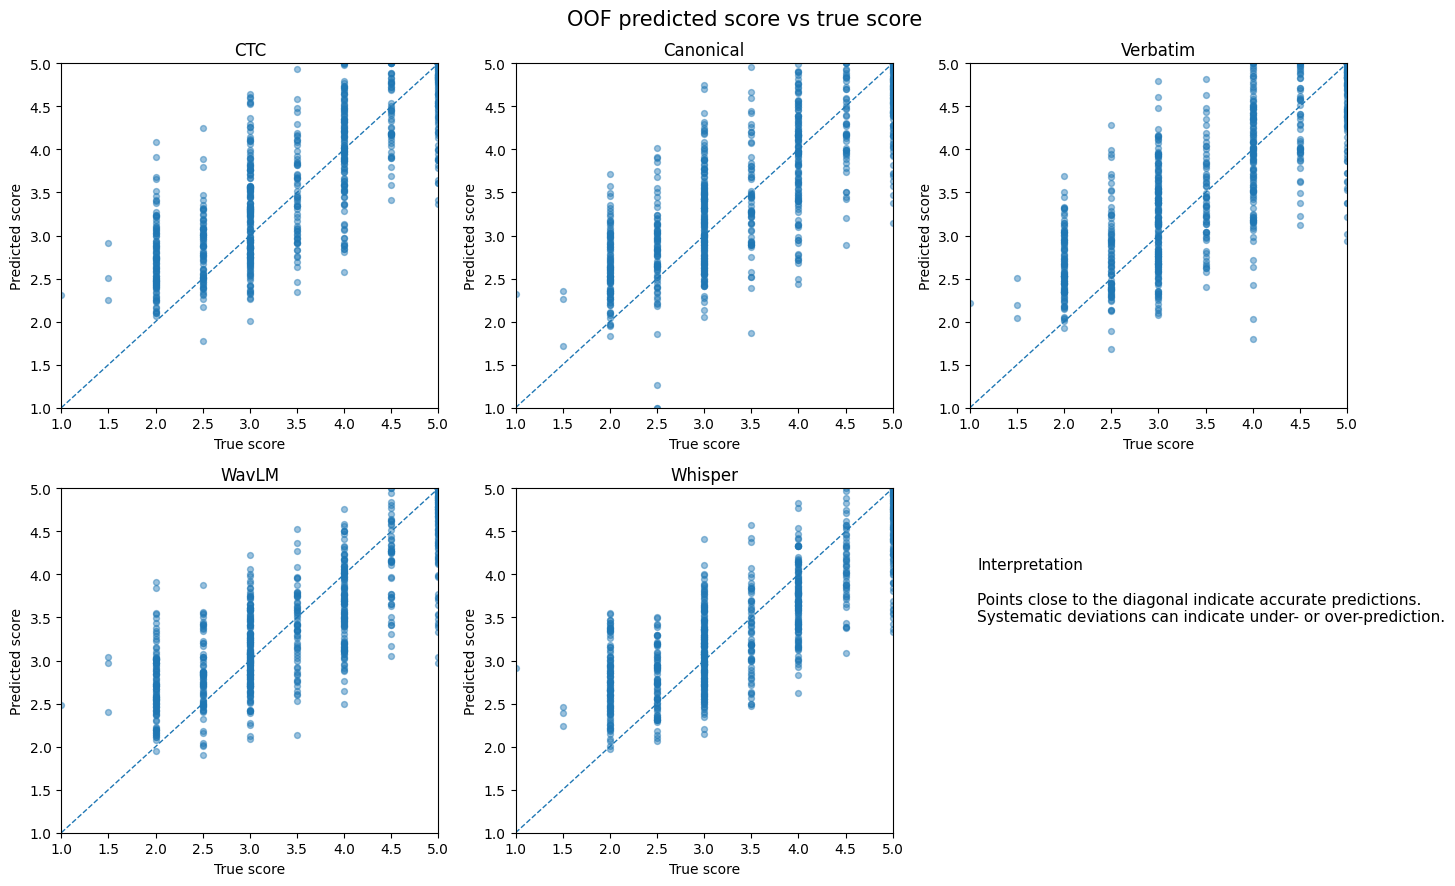

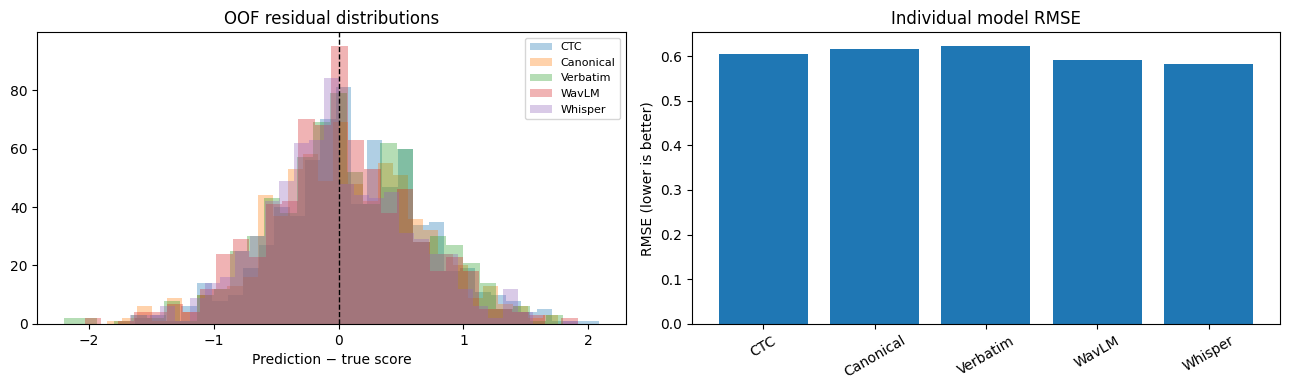

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for i, name in enumerate(MODEL_ORDER):
    pred = np.clip(model_oof[name], 1, 5)
    axes[i].scatter(y, pred, alpha=0.45, s=18)
    axes[i].plot([1, 5], [1, 5], linestyle="--", linewidth=1)
    axes[i].set_title(name)
    axes[i].set_xlabel("True score")
    axes[i].set_ylabel("Predicted score")
    axes[i].set_xlim(1, 5)
    axes[i].set_ylim(1, 5)

axes[5].axis("off")
axes[5].text(
    0.02, 0.8,
    "Interpretation\n\n"
    "Points close to the diagonal indicate accurate predictions.\n"
    "Systematic deviations can indicate under- or over-prediction.",
    fontsize=11, va="top"
)
plt.suptitle("OOF predicted score vs true score", fontsize=15)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in MODEL_ORDER:
    residual = np.clip(model_oof[name], 1, 5) - y
    axes[0].hist(residual, bins=30, alpha=0.35, label=name)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("OOF residual distributions")
axes[0].set_xlabel("Prediction − true score")
axes[0].legend(fontsize=8)

rmse_values = individual_results.set_index("Model")["RMSE (clipped)"].reindex(MODEL_ORDER)
axes[1].bar(rmse_values.index, rmse_values.values)
axes[1].set_title("Individual model RMSE")
axes[1].set_ylabel("RMSE (lower is better)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 11. Error analysis by true score

This breakdown checks whether errors differ across the score range. A model can have a good overall RMSE while struggling with rare or extreme target values.

,true_score,Count,MAE,Mean_residual,Model
0,1.0,1,1.304688,1.304688,CTC
1,1.5,3,1.056171,1.056171,CTC
2,2.0,102,0.747227,0.747227,CTC
3,2.5,79,0.409267,0.346152,CTC
4,3.0,174,0.473653,0.237581,CTC
5,3.5,64,0.462239,-0.029276,CTC
6,4.0,124,0.437658,-0.004422,CTC
7,4.5,52,0.352186,-0.098913,CTC
8,5.0,133,0.347209,-0.347209,CTC
9,1.0,1,1.316578,1.316578,Canonical


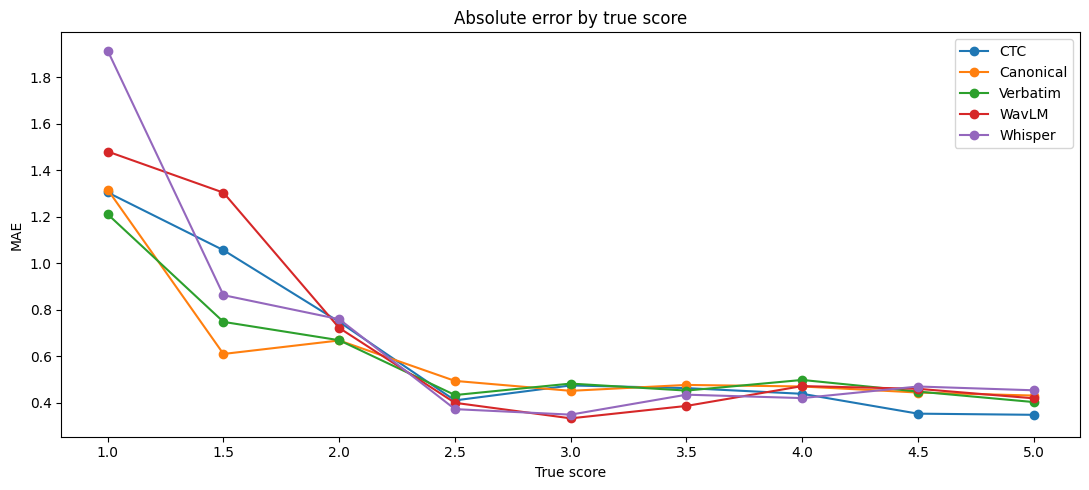

In [11]:
error_rows = []
for name in MODEL_ORDER:
    pred = np.clip(model_oof[name], 1, 5)
    residual = pred - y
    temp = pd.DataFrame({"true_score": y, "abs_error": np.abs(residual), "residual": residual})
    by_score = temp.groupby("true_score").agg(
        Count=("abs_error", "size"),
        MAE=("abs_error", "mean"),
        Mean_residual=("residual", "mean"),
    ).reset_index()
    by_score["Model"] = name
    error_rows.append(by_score)

error_by_score = pd.concat(error_rows, ignore_index=True)
display(error_by_score.head(25))

fig, ax = plt.subplots(figsize=(11, 5))
for name in MODEL_ORDER:
    part = error_by_score[error_by_score["Model"] == name]
    ax.plot(part["true_score"], part["MAE"], marker="o", label=name)
ax.set_xlabel("True score")
ax.set_ylabel("MAE")
ax.set_title("Absolute error by true score")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Ensemble evaluation

The final ensemble is a **non-negative linear stacker**. We evaluate the stacker using five-fold cross-validation over the saved OOF prediction matrix. The stacker therefore learns from base-model predictions rather than raw audio or text.

This is a second-level evaluation: its reliability depends on the quality and fold provenance of the saved base OOF predictions. Since the saved files came from separate experiments, fold compatibility cannot be guaranteed from array shapes alone. Treat these metrics as an informative estimate, not a substitute for a fully nested end-to-end evaluation.

In [12]:
stack_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stack_model = LinearRegression(positive=True)

stack_oof_raw = cross_val_predict(
    stack_model, P, y, cv=stack_cv, n_jobs=-1
)
stack_oof = np.clip(stack_oof_raw, 1.0, 5.0)

stack_metrics = calculate_metrics(y, stack_oof)
stack_results = pd.DataFrame(
    [{"Model": "Non-negative linear stack", **stack_metrics}]
)

print("Cross-validated stack metrics:")
display(stack_results)

# Compare all individual OOF predictions and the CV stack.
comparison = individual_results[["Model", "RMSE (clipped)", "MAE (clipped)", "Pearson r", "R² (clipped)"]].copy()
comparison = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "Non-negative linear stack (CV)",
        "RMSE (clipped)": stack_metrics["RMSE (clipped)"],
        "MAE (clipped)": stack_metrics["MAE (clipped)"],
        "Pearson r": stack_metrics["Pearson r"],
        "R² (clipped)": stack_metrics["R² (clipped)"],
    }])
], ignore_index=True)
display(comparison.sort_values("RMSE (clipped)").reset_index(drop=True))

Cross-validated stack metrics:


,Model,RMSE (clipped),MAE (clipped),Pearson r,R² (clipped),Prediction min,Prediction max
0,Non-negative linear stack,0.495771,0.381186,0.872509,0.760822,1.565752,5.0


,Model,RMSE (clipped),MAE (clipped),Pearson r,R² (clipped)
0,Non-negative linear stack (CV),0.495771,0.381186,0.872509,0.760822
1,Whisper,0.583209,0.459272,0.820697,0.669016
2,WavLM,0.591130,0.451920,0.813261,0.659964
3,CTC,0.605535,0.469649,0.812475,0.643190
4,Canonical,0.616168,0.488323,0.797048,0.630548
5,Verbatim,0.621969,0.487574,0.794867,0.623560


## 13. Fit the final stack and inspect its learned weights

After cross-validated evaluation, fit the stacker on all eligible OOF rows for final test inference. These coefficients describe how the second-stage model combines the five base predictions; they are not feature-level explanations of the neural models.

Intercept: -0.6042916821601207


,Base model,Weight
0,WavLM,0.405536
1,CTC,0.246710
2,Canonical,0.207095
3,Whisper,0.198992
4,Verbatim,0.099551


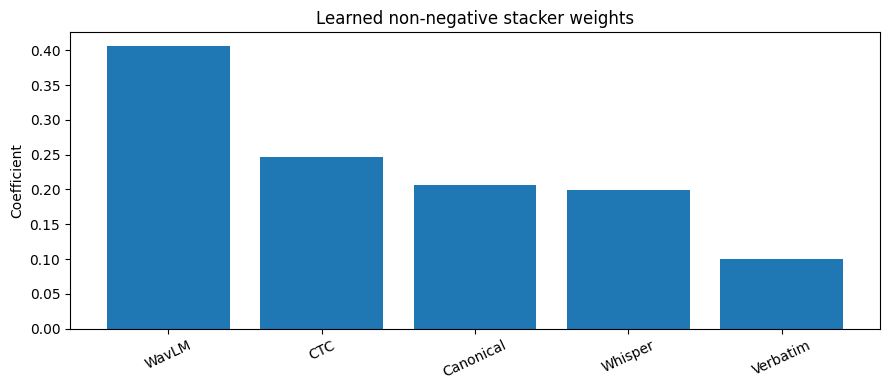

In [13]:
final_stacker = LinearRegression(positive=True)
final_stacker.fit(P, y)

weight_table = pd.DataFrame({
    "Base model": MODEL_ORDER,
    "Weight": final_stacker.coef_,
}).sort_values("Weight", ascending=False)

print("Intercept:", float(final_stacker.intercept_))
display(weight_table.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weight_table["Base model"], weight_table["Weight"])
ax.set_title("Learned non-negative stacker weights")
ax.set_ylabel("Coefficient")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 14. Test-set inference and submission validation

The final stacker is applied to the five saved/generated test prediction vectors. Predictions are clipped to the expected score range and exported in the competition submission format.

In [14]:
test_pred_raw = final_stacker.predict(P_test)
test_pred = np.clip(test_pred_raw, 1.0, 5.0)

submission = test_df[["filename"]].copy()
submission["label"] = test_pred

assert submission.shape == (len(test_df), 2)
assert submission["filename"].equals(test_df["filename"])
assert submission["label"].notna().all()
assert np.isfinite(submission["label"]).all()
assert submission["label"].between(1.0, 5.0).all()

OUTPUT_DIR = Path("/kaggle/working/grammar_scoring_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

print("Submission saved:", SUBMISSION_PATH)
print("Shape:", submission.shape)
print("Prediction range:", (float(submission["label"].min()), float(submission["label"].max())))
print("\nPrediction summary:")
display(submission["label"].describe().to_frame("predicted_label"))
display(submission.head(10))

Submission saved: /kaggle/working/grammar_scoring_final/submission.csv
Shape: (216, 2)
Prediction range: (1.5275173656089005, 5.0)

Prediction summary:


,predicted_label
count,216.000000
mean,3.314210
std,0.826358
min,1.527517
25%,2.618938
50%,3.196427
75%,3.820864
max,5.000000


,filename,label
0,audio_128.wav,3.071190
1,audio_156.wav,3.948581
2,audio_19.wav,4.497983
3,audio_108.wav,2.117714
4,audio_206.wav,2.269007
5,audio_161.wav,2.926527
6,audio_215.wav,2.968965
7,audio_213.wav,2.256902
8,audio_11.wav,3.706937
9,audio_155.wav,3.137721


## 15. Final evaluation summary

- The notebook evaluates five saved base-model OOF prediction streams and a cross-validated second-level stack.
- It reports RMSE, MAE, Pearson correlation, and \(R^2\), alongside diagnostic plots and error breakdowns.
- It reuses saved transcript-model predictions, WavLM predictions, and Whisper embeddings. No ASR transcription or neural fine-tuning is performed.
- The final submission is written to ` /kaggle/working/grammar_scoring_final/submission.csv `.

### Limitations

1. The OOF arrays were generated in prior runs. This notebook checks dimensions, finite values, and expected row counts, but cannot prove the exact fold construction of every artifact.
2. The second-stage CV score is an estimate based on the saved prediction matrix. Since the base predictions originate from separate experiments, the score may be optimistic if their OOF folds are not fully compatible.
3. The competition leaderboard score depends on the hidden test labels and is not reproducible from the public training labels alone.
4. The previous public submission score of **0.3412** is recorded as context; this notebook does not claim the newly generated file will improve it.